# Round 2: tuning and finalists (validation only)

Presents the outputs of `pipelines/05_round2.py`. The test set is locked.

In [1]:
from frostwatch_ml.evaluation import notebook as nb
from frostwatch_ml.evaluation import plots

In [2]:
nb.show_markdown(nb.markdown("reports/round2/finalists.md"))

# Round 2 finalists (validation only; test pending)

| finalist | model_version | role | params | calibrated | threshold | pr_auc | f2 | macro_pr_auc | macro_f2 |
|---|---|---|---|---|---|---|---|---|---|
| LR_best | lr-20261103-fbbf62c6 | production_candidate | {'C': 1.0, 'class_weight': None, 'penalty': 'l1'} | True | 0.1724 | 0.8918 | 0.8757 | 0.8374 | 0.8570 |
| TREE_best | lightgbm-20261103-fbbf62c6 | comparison_only | {'n_estimators': 800, 'learning_rate': 0.02, 'num_leaves': 31, 'min_child_samples': 100, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.6, 'reg_lambda': 1.0} | False | 0.1705 | 0.9105 | 0.8819 | 0.8624 | 0.8627 |

Gap LR_best minus TREE_best, pooled: pr_auc -0.0187, f2 -0.0062, roc_auc -0.0086, brier +0.0066; macro: pr_auc -0.0250, f2 -0.0057.


In [3]:
nb.csv("reports/round2/lr_grid.csv", index_col=None).sort_values("pr_auc", ascending=False).head(10)

,C,class_weight,penalty,pr_auc,f2,roc_auc,brier,threshold,macro_pr_auc,macro_f2
25,1.000,none,l1,0.891827,0.875738,0.942632,0.091334,0.171910,0.837384,0.857022
29,3.160,none,l1,0.891822,0.875668,0.942627,0.091343,0.172310,0.837399,0.856853
41,100.000,none,l1,0.891794,0.875855,0.942630,0.091342,0.164659,0.837321,0.857049
33,10.000,none,l1,0.891791,0.875788,0.942629,0.091342,0.164064,0.837314,0.856925
37,31.600,none,l1,0.891789,0.875794,0.942628,0.091342,0.164486,0.837314,0.856967
40,100.000,none,l2,0.891775,0.875577,0.942604,0.091354,0.181243,0.837414,0.856634
36,31.600,none,l2,0.891770,0.875610,0.942614,0.091357,0.205390,0.837391,0.856801
21,0.316,none,l1,0.891750,0.876130,0.942610,0.091352,0.168719,0.836939,0.857449
32,10.000,none,l2,0.891750,0.875630,0.942602,0.091372,0.155847,0.837374,0.856861
28,3.160,none,l2,0.891729,0.875715,0.942611,0.091363,0.175884,0.837376,0.856677


In [4]:
nb.csv("reports/round2/tree_search.csv", index_col=None).sort_values("pr_auc", ascending=False).head(10)

,draw,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,subsample_freq,colsample_bytree,reg_lambda,pr_auc,f2,roc_auc,brier,threshold,macro_pr_auc,macro_f2
10,10,800,0.02,31,100,0.8,1,0.6,1.0,0.910483,0.881905,0.951250,0.084741,0.170481,0.862423,0.862693
17,17,400,0.02,63,50,0.6,1,0.6,0.0,0.910296,0.882133,0.951097,0.084725,0.164807,0.861603,0.863089
28,28,200,0.05,63,50,0.8,1,1.0,0.0,0.909765,0.882609,0.950734,0.085284,0.192606,0.861191,0.863395
1,1,100,0.1,63,20,0.8,1,1.0,0.0,0.909263,0.881965,0.950520,0.085238,0.188951,0.860675,0.862276
5,5,400,0.02,31,10,0.6,1,0.8,5.0,0.908724,0.882442,0.950428,0.085261,0.167315,0.859392,0.863198
6,6,100,0.1,127,20,0.8,1,0.6,5.0,0.908715,0.881995,0.950305,0.085646,0.153913,0.859243,0.862817
30,30,400,0.02,31,100,1.0,1,0.6,5.0,0.908456,0.881870,0.950153,0.085538,0.181982,0.858391,0.862385
24,24,400,0.02,31,20,1.0,1,0.6,0.0,0.908033,0.881053,0.949957,0.085723,0.154151,0.858072,0.861756
27,27,200,0.05,31,20,0.6,1,0.8,0.0,0.907991,0.881791,0.950102,0.085717,0.157540,0.858790,0.862180
15,15,400,0.01,127,10,1.0,1,0.6,5.0,0.907889,0.880925,0.949771,0.085612,0.185825,0.858677,0.861605


In [5]:
nb.show_markdown(nb.markdown("reports/round2/comparison_macro.md"))

# Round 2 finalists vs baselines, validation, macro over cells

| model | accuracy | majority_class_accuracy | precision | recall | f1 | f2 | roc_auc | pr_auc | brier |
|---|---|---|---|---|---|---|---|---|---|
| climatology | 0.7593 | 0.6932 | 0.5661 | 0.9432 | 0.7037 | 0.8281 | 0.8914 | 0.7310 | 0.1195 |
| persistence | 0.8386 | 0.6932 | 0.7176 | 0.7176 | 0.7176 | 0.7176 | 0.7932 | 0.6060 | 0.1614 |
| LR_best | 0.8148 | 0.6932 | 0.6238 | 0.9565 | 0.7477 | 0.8570 | 0.9359 | 0.8374 | 0.0913 |
| TREE_best | 0.8232 | 0.6932 | 0.6331 | 0.9566 | 0.7566 | 0.8627 | 0.9441 | 0.8624 | 0.0847 |


In [6]:
lr_dir = nb.latest_model_dir("lr")
nb.csv(lr_dir + "/coefficients.csv", index_col=None).head(12)

,feature,std_coefficient,train_mean,train_std
0,strd_1800_wm2,-5.533976,263.462859,39.503751
1,sky_emissivity_1800,5.306524,0.717261,0.114078
2,rh_1800_pct,-2.035942,42.900241,24.154556
3,doy_cos,-1.876638,-0.000137,0.707058
4,prev_night_tmin_c,-1.000186,0.788690,3.642115
5,afternoon_clearness,-0.979233,0.844236,0.128473
6,ssrd_afternoon_mean_wm2,0.855079,727.308280,122.853809
7,d2m_1800_c,0.704022,-4.572572,9.823351
8,ssrd_1800_wm2,0.632605,155.245316,65.001559
9,elevation_proxy_m,0.486986,3834.567902,117.071645


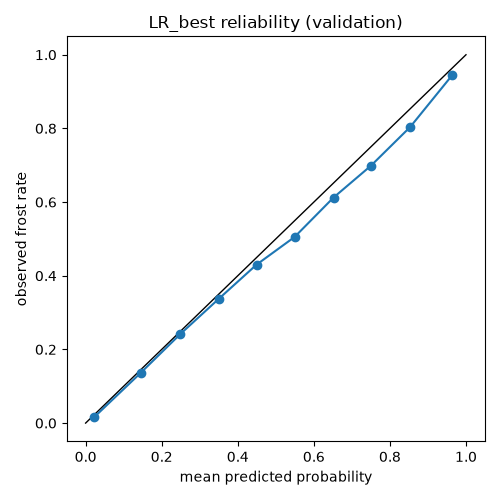

In [7]:
nb.figure(plots.reliability(nb.csv(lr_dir + "/reliability_bins.csv", index_col=None), "LR_best reliability (validation)"))

In [8]:
card = nb.load_json(lr_dir + "/model_card.json")
print(card["status"])
card["limitations"]

validation metrics only; test pending


['Labels come from the same ERA5-Land reanalysis as the features: the model predicts grid frost (0.1 degree cell), which is smoother than frost at a station or in a cold hollow.',
 'ERA5-Land cells are about 9 km; local terrain and cold air pooling are not resolved.',
 'Cloud information is a lagged proxy (AgERA5 24 h mean of the previous day); AgERA5 has its own 0.1 degree grid, which coincides with the ERA5-Land cells for these 8 points but can be offset by up to about 7 km in general.',
 'Frost nights trend down over 1985-2025, so the test years (2018-2025) have a lower base rate than training (1985-2009).',
 'Latitude and the elevation proxy are constants of the 8 training cells: the model is valid only for these 8 cells.',
 'Data is reanalysis (published a few days late), not a live forecast; the model has not been evaluated on forecast inputs.',
 'No confidence intervals are computed; small metric differences may be noise.']